In [30]:
import os
import torch
import sys

# Keep deterministic behavior and workspace config, but remove expandable_segments
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

# Optional: If you still want to tweak allocation on Windows, you can use max_split_size_mb
# os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'max_split_size_mb:128'

torch.backends.cudnn.benchmark = False

print(f"Python: {sys.version}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Compute capability: {torch.cuda.get_device_capability(0)}")
    
    # Quick sanity check
    x = torch.randn(100, 100, device='cuda')
    y = x @ x.T
    print(f"✅ CUDA matmul successful: {y.shape}")

Python: 3.10.18 | packaged by Anaconda, Inc. | (main, Jun  5 2025, 13:08:55) [MSC v.1929 64 bit (AMD64)]
PyTorch: 2.12.0.dev20260408+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti
Compute capability: (12, 0)
✅ CUDA matmul successful: torch.Size([100, 100])


In [31]:
import os
from joblib import Parallel, delayed
import sqlite3
import polars as pl
from collections import defaultdict
import numpy as np
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
import time
from tqdm import tqdm
import networkx as nx
import copy
import random
import pickle
from shapely.geometry import Polygon, Point
from shapely.ops import transform
from pyproj import Transformer
from typing import Dict, List, Tuple
import warnings
import json
import re

rng = np.random.default_rng (seed = 42)

MPID_df = pl.read_json('ml_ozon_logistic_dataSetOrders.json')

MPIDs_dict = defaultdict(list)
orders_dict = defaultdict(list)
orders_geo = defaultdict(list)

for item in MPID_df['Orders'].to_list():
    for order in item:
        if order['ID'] != 0:
            orders_geo[order['ID']] = {
                'lat': order['Lat'],
                'lon': order['Long']
            }
            MPIDs_dict[order['MpId']].append(order['ID'])
            orders_dict[order['ID']] = order['MpId']
        
MPIDs_list = list(MPIDs_dict.keys())

print(f"Загружено {len(orders_geo)} заказов, {len(MPIDs_list)} MPID")

def load_couriers_data(file_path):
    """Загружает данные о курьерах с координатами из Warehouse"""
    with open(file_path, 'r') as f:
        data = json.load(f)
    
    warehouse_geo = {
        'lat': data['Warehouse']['Lat'],
        'lon': data['Warehouse']['Long']
    }
    
    couriers = []
    for courier_group in data['Couriers']:
        courier_id = courier_group['ID']
        service_times = {}
        for service_time in courier_group['ServiceTimeInMps']:
            service_times[service_time['MpID']] = service_time['ServiceTime']
        
        couriers.append({
            'id': courier_id,
            'service_times': service_times
        })
    
    return warehouse_geo, couriers

warehouse_geo, couriers_data = load_couriers_data('ml_ozon_logistic_dataSetCouriers.json')
all_couriers_IDs = [c['id'] for c in couriers_data]

print(f"Загружено {len(couriers_data)} курьеров, склад: ({warehouse_geo['lat']}, {warehouse_geo['lon']})")

Загружено 20159 заказов, 1393 MPID
Загружено 280 курьеров, склад: (55.855153, 36.801776)


In [32]:
def create_sorted_distance_array():
    """Создает отсортированный массив расстояний с возможностью быстрого поиска"""
    conn = sqlite3.connect('distances.db')
    cursor = conn.cursor()

    # Получаем общее количество строк
    cursor.execute('SELECT COUNT(*) FROM distances')
    total_rows = cursor.fetchone()[0]

    # Создаем memory-mapped файл
    mmap_array = np.memmap('distances.dat', dtype=np.int32, mode='w+', shape=(total_rows, 3))

    # Загружаем данные из базы
    cursor.execute("SELECT from_location, to_location, distance FROM distances ORDER BY from_location, to_location")

    batch_size = 100000
    index = 0

    progress_bar = tqdm(total=total_rows, desc="Создание отсортированного массива", unit="row")

    while True:
        rows = cursor.fetchmany(batch_size)
        if not rows:
            break

        batch_array = np.array(rows, dtype=np.int32)
        mmap_array[index:index+len(batch_array)] = batch_array
        index += len(batch_array)

        progress_bar.update(len(rows))

    progress_bar.close()
    conn.close()

    return mmap_array

def create_search_index(distance_array):
    """Создает индекс для быстрого поиска по from_location"""
    # Находим уникальные from_location и их начальные позиции
    unique_from, start_indices = np.unique(distance_array[:, 0], return_index=True)

    # Создаем словарь для быстрого поиска диапазонов
    index_dict = {}
    for i in range(len(unique_from)):
        start = start_indices[i]
        end = start_indices[i+1] if i+1 < len(start_indices) else len(distance_array)
        index_dict[unique_from[i]] = (start, end)

    return index_dict

print("создание numpy сета расстояний из базы данных...")
start_time = time.time()

with open('distances.dat', 'rb') as f:
    data_bytes = f.read()
    
distance_array = np.frombuffer(data_bytes, dtype=np.int32).reshape(-1, 3)

# distance_array = create_sorted_distance_array()

idx_dict = create_search_index(distance_array)
cache_time = time.time() - start_time
print(f"Кэш создан за {cache_time:.2f} секунд, всего {len(distance_array)} записей")

создание numpy сета расстояний из базы данных...
Кэш создан за 6.78 секунд, всего 406405440 записей


In [33]:
def get_distance(distance_array, idx_dict, from_point, to_point, default=10**9):
    """Быстрое получение расстояния между двумя точками"""
    if from_point not in idx_dict:
        return default

    start, end = idx_dict[from_point]

    # Бинарный поиск в отсортированном диапазоне
    subset = distance_array[start:end]
    to_points = subset[:, 1]

    # Используем бинарный поиск NumPy
    pos = np.searchsorted(to_points, to_point)

    if pos < len(to_points) and to_points[pos] == to_point:
        return subset[pos, 2]
    else:
        return default

def create_distance_matrix(points, distance_array, idx_dict, poly_mapping=None, punishment=8000):
    """Создает матрицу расстояний для точек полигона с учетом штрафов между разными полигонами"""
    n = len(points)
    matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                matrix[i][j] = 0
            else:
                distance = get_distance(distance_array, idx_dict, points[i], points[j])
                
                if poly_mapping is not None:
                    poly_i = poly_mapping[points[i]]
                    poly_j = poly_mapping[points[j]]
                    
                    if poly_i != poly_j:
                        matrix[i][j] = distance + punishment
                    else:
                        matrix[i][j] = distance
                else:
                    matrix[i][j] = distance

    return matrix.astype(int).tolist()

def get_basic_order_ID(point):
    sliced_string = re.split(r'-', str(point))
    basic_point = sliced_string[-1]

    return int(basic_point)

In [34]:
from ortools.linear_solver import pywraplp
import uuid
import tempfile
import os
import subprocess
import numpy as np
import sys
from io import StringIO
from contextlib import redirect_stdout, redirect_stderr

def solve_lkh_atsp(points, start, dist, runs=5):    
    if isinstance(dist, list):
        dist = np.array(dist)
    
    # Validate input
    if len(dist.shape) != 2:
        raise ValueError(f"Distance matrix must be 2D, got {dist.shape}")
    
    n = dist.shape[0]
    
    if n < 3:
        raise ValueError(f"LKH-3 requires at least 3 nodes, but got {n}")
    
    if dist.shape[0] != dist.shape[1]:
        raise ValueError(f"Distance matrix must be square, got {dist.shape}")
    

    modified_dist = dist.copy()
    BIG = 10**5

    for i in range(n):
        if i != start:
            modified_dist[i, start] = BIG

    uid = uuid.uuid4().hex
    lkh_dir = r"D:\LKHWin-3.0.13"
    lkh_executable = os.path.join(lkh_dir, "LKH-3.exe")

    tmp_dir = os.path.join(lkh_dir, f"tmp_{uid}")
    os.makedirs(tmp_dir, exist_ok=True)

    try:
        tsp_path = os.path.join(tmp_dir, f"{uid}.tsp")
        par_path = os.path.join(tmp_dir, f"{uid}.par")
        tour_path = os.path.join(tmp_dir, f"{uid}.tour")

        # FIX 1: Strict TSPLIB formatting (no spaces before colons, standard '\n' line endings)
        with open(tsp_path, "w", encoding='ascii') as f:
            f.write(f"NAME: atsp_open\n")
            f.write(f"TYPE: ATSP\n")
            f.write(f"DIMENSION: {n}\n")
            f.write(f"EDGE_WEIGHT_TYPE: EXPLICIT\n")
            f.write(f"EDGE_WEIGHT_FORMAT: FULL_MATRIX\n")
            f.write(f"EDGE_WEIGHT_SECTION\n")
            for i in range(n):
                # Ensure values are integers to prevent float formatting issues
                row = [str(int(modified_dist[i, j])) for j in range(n)]
                f.write(" ".join(row) + "\n")
            f.write("EOF\n")

        # FIX 2: Explicitly force PRECISION = 1 to bypass the buggy "too large" check 
        # in some LKH-3 Windows builds. It is ignored anyway for EXPLICIT matrices.
        with open(par_path, "w", encoding='ascii') as f:
            f.write(f"PROBLEM_FILE = {tsp_path}\n")
            f.write(f"OUTPUT_TOUR_FILE = {tour_path}\n")
            f.write(f"RUNS = {runs}\n")
            f.write(f"PRECISION = 1\n")
            f.write(f"TRACE_LEVEL = 0\n")
            f.write("EOF\n")

        result = subprocess.run(
            [lkh_executable, par_path],
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            check=False,
            text=True,
            cwd=lkh_dir
        )

        if result.returncode != 0:
            print("LKH-3 Error:")
            print("STDOUT:", result.stdout)
            print("STDERR:", result.stderr)
            raise subprocess.CalledProcessError(result.returncode, result.args)

        with open(tour_path, encoding='ascii') as f:
            lines = f.readlines()

        tour = []
        for line in lines:
            if line.strip().isdigit():
                v = int(line.strip()) - 1
                tour.append(v)

        if start in tour:
            idx = tour.index(start)
            tour = tour[idx:] + tour[:idx]

        lkh_route = [points[i] for i in tour]
        
        total_distance = 0
        for i in range(len(tour) - 1):
            total_distance += dist[tour[i], tour[i + 1]]
            
        return lkh_route, total_distance

    finally:
        import shutil
        if os.path.exists(tmp_dir):
            shutil.rmtree(tmp_dir)

def solve_TSP_branch_and_cut(points, prev_point, matrix_to_solve, max_time_s=5):
    depot = 0

    n = len(points)
    if n == 0:
        return [], 0, None, None
    if n == 1:
        return [points[0]], 0, points[0], points[0]

    # Создаём solver (CBC)
    solver = pywraplp.Solver.CreateSolver("SCIP")
    
    x = {}
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            x[i, j] = solver.BoolVar(f"x[{i},{j}]")

    # Не возвращаемся в depot: out = 1, in = 0
    solver.Add(solver.Sum(x[depot, j] for j in range(n) if j != depot) == 1)
    solver.Add(solver.Sum(x[i, depot] for i in range(n) if i != depot) == 0)

    # для остальных вершин: in = 1, out <= 1
    for i in range(n):
        if i == depot:
            continue
        solver.Add(solver.Sum(x[j, i] for j in range(n) if j != i) == 1)
        solver.Add(solver.Sum(x[i, j] for j in range(n) if j != i) <= 1)

    # минимизация суммарного времени
    solver.Minimize(solver.Sum(matrix_to_solve[i][j] * x[i, j]
                                for i in range(n) for j in range(n) if i != j))

    def extract_subtours_from_solution():
        """
        Возвращает список замкнутых циклов по текущему решению x
        """
        succ = [None] * n
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                val = x[i, j].solution_value()
                if val is not None and val > 0.5:
                    succ[i] = j
                    break  # у каждой вершины максимум один исходящий путь
    
        visited_global = set()
        subtours = []
    
        for start in range(n):
            if start in visited_global:
                continue
    
            cur = start
            seen_local = set()
    
            while cur is not None:
                if cur in seen_local:
                    # нашли цикл — восстанавливаем его
                    cycle = []
                    node = cur
                    while node is not None and node not in cycle:
                        cycle.append(node)
                        node = succ[node]
                        if node == cur:
                            break
    
                    if cycle:
                        subtours.append(cycle)
                    break
    
                if cur in visited_global:
                    # Уже посещали эту вершину ранее — цикл не образуется
                    break
    
                seen_local.add(cur)
                visited_global.add(cur)
                cur = succ[cur]  # переход к следующему узлу
                
        return subtours


    status = None
    solver.SetTimeLimit(int(max_time_s * 1000))
    while True:
        status = solver.Solve()

        if status == pywraplp.Solver.OPTIMAL or status == pywraplp.Solver.FEASIBLE:
            subtours = extract_subtours_from_solution()
            if len(subtours) == 0:
                break

            added = 0
            for S in subtours:
                if depot in S:
                    continue
                if len(S) <= 1:
                    continue
                solver.Add(solver.Sum(x[i, j] for i in S for j in S if i != j) <= len(S) - 1)
                added += 1

            if added == 0:
                break
            continue
        else:
            break
    # or status == pywraplp.Solver.FEASIBLE        
    if status == pywraplp.Solver.OPTIMAL: 
        succ = [-1] * n
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                val = x[i, j].solution_value()
                if val is not None and val > 0.5:
                    succ[i] = j
                    break

        route_idx = []
        cur = depot
        route_idx.append(cur)
        visited = set([cur])
        while True:
            nxt = succ[cur]
            if nxt == -1 or nxt is None:
                break
            route_idx.append(nxt)
            if nxt in visited:
                # защита от зацикливания — остановимся
                break
            visited.add(nxt)
            cur = nxt
            if len(visited) >= n:
                break

        # путь не замыкаем
        # вычислим расстояние по ребрам пути
        total_distance = 0
        for k in range(len(route_idx) - 1):
            i = route_idx[k]
            j = route_idx[k + 1]
            total_distance += matrix_to_solve[i][j]

        route_points = [points[i] for i in route_idx]
        start_point = points[depot]
        end_point = points[route_idx[-1]]

        return route_points, total_distance, start_point, end_point

def solve_TSP_Christofides_inner(points, prev_point, matrix_to_solve):
    n = len(points)
    if n == 0:
        return [], 0, None, None
    elif n == 1:
        single_point = points[0]
        return [single_point], 0, single_point, single_point

    added_prev = False
    if prev_point not in points:
        points = [prev_point] + points
        added_prev = True
    
    depot = 0
    
    manager = pywrapcp.RoutingIndexManager(
        len(matrix_to_solve), 1, depot
    )

    routing = pywrapcp.RoutingModel(manager)

    index_to_node_cache = {}
    
    for node in range(len(matrix_to_solve)):
        idx = manager.NodeToIndex(node)
        index_to_node_cache[idx] = node
    
    start_idx = routing.Start(0)
    index_to_node_cache[start_idx] = manager.IndexToNode(start_idx)
    
    end_idx = routing.End(0)
    index_to_node_cache[end_idx] = manager.IndexToNode(end_idx)

    def distance_callback(from_index, to_index, _dm=matrix_to_solve, _idx=index_to_node_cache, _dep=depot):
        from_node = _idx[from_index]
        to_node = _idx[to_index]
        return 0 if to_node == _dep else int(_dm[from_node][to_node])

    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    search_parameters = pywrapcp.DefaultRoutingSearchParameters()
    search_parameters.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.CHRISTOFIDES
    )

    solution = routing.SolveWithParameters(search_parameters)

    if solution:
        index = routing.Start(0)
        route = []
        route_distance = 0
        
        if added_prev:
            index = solution.Value(routing.NextVar(index))
        
        start_node = index_to_node_cache[index]
        
        while not routing.IsEnd(index):
            node_index = index_to_node_cache[index]
            route.append(node_index)
            previous_index = index
            index = solution.Value(routing.NextVar(index))
            route_distance += routing.GetArcCostForVehicle(previous_index, index, 0)

        end_node = index_to_node_cache[previous_index]
        
        result_route = [points[i] for i in route]
        
        if added_prev:
            start_point = points[start_node] if start_node > 0 else None
            end_point = points[end_node] if end_node > 0 else None
        else:
            start_point = points[start_node]
            end_point = points[end_node]

        return result_route, route_distance, start_point, end_point

In [35]:
import pickle
from collections import defaultdict

with open('optimized_solution_fast.pkl', 'rb') as file:
    final_solution = pickle.load(file)

with open('each_polygon_opt_route.pkl', 'rb') as file:
    final_each_polygon_opt_route = pickle.load(file)

with open('AUG_global_map.pkl', 'rb') as file:
    AUG_global_map = pickle.load(file)

with open('epos_cache.pkl', 'rb') as file:
    test_epos = pickle.load(file)

with open('global_properties.pkl', 'rb') as file:
    properties = pickle.load(file)

with open('Routes_cache.pkl', 'rb') as file:
    optimal_routes_ds = pickle.load(file)

In [36]:
optimal_routes_ds_clean = {}

for item,val in optimal_routes_ds.items():
    if val!=[]:
        optimal_routes_ds_clean[item] = val

In [37]:
import math
import copy
from typing import Optional, List, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR


# ============================================================
# 1. Mixed-Score Multi-Head Attention  (THE core of MatNet)
#    Fuses the scaled dot-product score with the raw matrix
#    entry (distance) through a tiny MLP "mixer".
# ============================================================
class MixedScoreMHA(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, ms_hidden: int = 16):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.n_heads, self.head_dim = n_heads, embed_dim // n_heads
        self.Wq = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wk = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv = nn.Linear(embed_dim, embed_dim, bias=False)
        self.out = nn.Linear(embed_dim, embed_dim, bias=False)
        # mixer: [dot_score, matrix_entry] -> fused score  (per head)
        self.mixer = nn.Sequential(nn.Linear(2, ms_hidden), nn.ReLU(),
                                   nn.Linear(ms_hidden, 1))

    def forward(self, q_in, kv_in, matrix, key_mask=None):
        # q_in:(B,Nq,E)  kv_in:(B,Nk,E)  matrix:(B,Nq,Nk)  key_mask:(B,Nk) True=valid
        B, Nq, _ = q_in.shape
        Nk = kv_in.size(1)
        H, hd = self.n_heads, self.head_dim
        q = self.Wq(q_in).view(B, Nq, H, hd).transpose(1, 2)
        k = self.Wk(kv_in).view(B, Nk, H, hd).transpose(1, 2)
        v = self.Wv(kv_in).view(B, Nk, H, hd).transpose(1, 2)
        dot = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(hd)   # (B,H,Nq,Nk)
        mat = matrix.unsqueeze(1).expand(-1, H, -1, -1)              # (B,H,Nq,Nk)
        scores = self.mixer(torch.stack([dot, mat], dim=-1)).squeeze(-1)
        if key_mask is not None:
            scores = scores.masked_fill(~key_mask[:, None, None, :], -1e9)
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, Nq, -1)
        return self.out(out)


# ============================================================
# 2. Dual-attention encoder block (rows <-> columns)
# ============================================================
class MatNetLayer(nn.Module):
    def __init__(self, embed_dim, n_heads, ff_dim, ms_hidden):
        super().__init__()
        self.row_attn = MixedScoreMHA(embed_dim, n_heads, ms_hidden)
        self.col_attn = MixedScoreMHA(embed_dim, n_heads, ms_hidden)
        self.rn1, self.rn2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
        self.cn1, self.cn2 = nn.LayerNorm(embed_dim), nn.LayerNorm(embed_dim)
        self.rff = nn.Sequential(nn.Linear(embed_dim, ff_dim), nn.ReLU(),
                                 nn.Linear(ff_dim, embed_dim))
        self.cff = nn.Sequential(nn.Linear(embed_dim, ff_dim), nn.ReLU(),
                                 nn.Linear(ff_dim, embed_dim))

    def forward(self, row, col, matrix, mask):
        # rows attend to columns through D ; columns attend to rows through D^T
        row = self.rn1(row + self.row_attn(row, col, matrix, mask))
        row = self.rn2(row + self.rff(row))
        col = self.cn1(col + self.col_attn(col, row, matrix.transpose(1, 2), mask))
        col = self.cn2(col + self.cff(col))
        return row, col


# ============================================================
# 3. Autoregressive decoder (Attention-Model style:
#    multi-head glimpse + single-head clipped logits)
# ============================================================
class MatNetDecoder(nn.Module):
    def __init__(self, embed_dim, n_heads, clip=10.0):
        super().__init__()
        self.n_heads, self.head_dim, self.clip = n_heads, embed_dim // n_heads, clip
        self.Wq   = nn.Linear(2 * embed_dim, embed_dim, bias=False)
        self.Wk   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv   = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wout = nn.Linear(embed_dim, embed_dim, bias=False)
        self.WkL  = nn.Linear(embed_dim, embed_dim, bias=False)

    def set_kv(self, node_emb):                       # cache K,V once per instance
        B, N, E = node_emb.shape
        H, hd = self.n_heads, self.head_dim
        self.gk = self.Wk(node_emb).view(B, N, H, hd).transpose(1, 2)
        self.gv = self.Wv(node_emb).view(B, N, H, hd).transpose(1, 2)
        self.lk = self.WkL(node_emb)
        self.scale = math.sqrt(E)

    def forward(self, query, visited):                # query:(B,2E) visited:(B,N) bool
        B, _ = query.shape
        E = self.lk.shape[-1]
        H, hd = self.n_heads, self.head_dim
        q = self.Wq(query).view(B, H, 1, hd)
        s = torch.matmul(q, self.gk.transpose(-2, -1)) / math.sqrt(hd)
        s = s.masked_fill(visited[:, None, None, :], -1e9)
        glimpse = torch.matmul(F.softmax(s, dim=-1), self.gv)         # (B,H,1,hd)
        glimpse = self.Wout(glimpse.transpose(1, 2).reshape(B, 1, E)).squeeze(1)
        logits = torch.matmul(glimpse.unsqueeze(1),
                              self.lk.transpose(1, 2)).squeeze(1) / self.scale
        logits = self.clip * torch.tanh(logits)
        return logits.masked_fill(visited, -1e9)


# ============================================================
# 4. The full MatNet model
# ============================================================
class MatNet(nn.Module):
    def __init__(self, embed_dim=128, n_layers=5, n_heads=8,
                 ff_dim=512, ms_hidden=16, clip=10.0):
        super().__init__()
        self.embed_dim = embed_dim
        self.layers = nn.ModuleList(
            [MatNetLayer(embed_dim, n_heads, ff_dim, ms_hidden) for _ in range(n_layers)])
        self.decoder = MatNetDecoder(embed_dim, n_heads, clip)
        self.track_diagnostics = False  # only first training batch of an epoch
        self.last_diagnostics = {}

    # MatNet initial embeddings: rows = zeros, columns = random one-hot ("instance
    # augmentation" replacement of node features for a featureless matrix).
    def _init_emb(self, B, N, device):
        row = torch.zeros(B, N, self.embed_dim, device=device)
        col = torch.zeros(B, N, self.embed_dim, device=device)
        idx = torch.rand(B, self.embed_dim, device=device).argsort(1)[:, :N]
        col.scatter_(2, idx.unsqueeze(-1), 1.0)
        return row, col

    def encode(self, dist, mask):
        B, N, _ = dist.shape
        
        # 1. Mask out the padded nodes BEFORE finding the maximum
        # mask shape is (B, N), we need it to be (B, 1, 1) or broadcastable to (B, N, N)
        valid_mask = mask.unsqueeze(1) & mask.unsqueeze(2) 
        masked_dist = dist.masked_fill(~valid_mask, 0.0)
        
        # 2. Calculate max ONLY on real nodes
        max_val = masked_dist.amax(dim=(1, 2), keepdim=True) + 1e-8
        
        # 3. Normalize
        mnorm = dist / max_val 
        
        row, col = self._init_emb(B, N, dist.device)
        for layer in self.layers:
            row, col = layer(row, col, mnorm, mask)
        return row, col                                              # node emb = rows

    def teacher_log_prob(self, dist, mask, target, n_nodes):
        """Log likelihood of a fixed depot-first LKH path under the current policy.

        This is an optional supervised auxiliary objective, not part of Kwon's
        original REINFORCE/POMO training. target uses the *current* node order.
        """
        B, N, _ = dist.shape
        if target.shape != (B, N):
            raise ValueError('LKH teacher shape does not match the padded matrix')
        if not torch.equal(target[:, 0], torch.zeros(B, dtype=torch.long, device=dist.device)):
            raise ValueError('LKH teachers must start at the depot')
        row, col = self.encode(dist, mask)
        self.decoder.set_kv(col)
        ar = torch.arange(B, device=dist.device)
        start = target[:, 0]
        cur = start
        visited = (~mask).scatter(1, start[:, None], True)
        path_logp = torch.zeros(B, dtype=dist.dtype, device=dist.device)
        for step in range(1, N):
            active = torch.as_tensor([n > step for n in n_nodes], device=dist.device)
            query = torch.cat((row[ar, cur], row[ar, start]), dim=-1)
            logits = self.decoder(query, visited)
            nxt = target[:, step]
            chosen_logp = F.log_softmax(logits, dim=-1).gather(1, nxt[:, None]).squeeze(1)
            path_logp = path_logp + torch.where(active, chosen_logp, 0.0)
            visited = visited.scatter(1, nxt[:, None], True)
            cur = nxt
        n_decisions = torch.as_tensor(n_nodes, device=dist.device).clamp_min(2) - 1
        return path_logp / n_decisions

    def decode(self, dist, mask, n_nodes, start_idx=None,
               decode_type='greedy', temperature=1.0):
        """Returns (tours:(B,N_max), sum_log_prob:(B,)). OPEN tour: no return edge."""
        B, N, _ = dist.shape
        device = dist.device
        if start_idx is None:
            start_idx = torch.zeros(B, dtype=torch.long, device=device)
        row, col = self.encode(dist, mask)
        self.decoder.set_kv(col)  # all candidate destinations use "to" embeddings
        entropy_sum = max_probability_sum = saturation_sum = active_steps = 0.0

        # NOTE: every update below is OUT-OF-PLACE so that the `visited`/`logits`
        # tensors saved by masked_fill for backward are never mutated afterwards.
        visited = (~mask).clone()                              # (B,N) bool
        visited = visited.scatter(1, start_idx[:, None], True) # out-of-place
        ar = torch.arange(B, device=device)
        cur = start_idx
        tours, logps = [start_idx], []

        for _ in range(N - 1):
            query = torch.cat((row[ar, cur], row[ar, start_idx]), dim=-1)
            logits = self.decoder(query, visited)  # current + initial "from" embeddings
            done = (logits <= -1e8).all(-1)                    # finished instances
            if done.any():
                # out-of-place self-loop fix (logp = 0 for finished rows)
                self_mask = torch.zeros_like(visited)
                self_mask[ar[done], cur[done]] = True          # fresh bool tensor, no grad
                logits = torch.where(self_mask,
                                     torch.zeros_like(logits), logits)

            probs = F.softmax(logits / temperature, -1)
            if self.track_diagnostics:
                with torch.no_grad():
                    active = ~done
                    if active.any():
                        p_active = probs[active]
                        entropy_sum += float((-(p_active * p_active.clamp_min(1e-12).log())
                                              .sum(-1)).sum().item())
                        max_probability_sum += float(p_active.max(-1).values.sum().item())
                        finite = logits[active].masked_fill(visited[active], 0.)
                        valid = (~visited[active]).sum().item()
                        saturation_sum += float((((finite.abs() >= .99 * self.decoder.clip)
                                                   & ~visited[active]).sum().item()) / max(valid, 1))
                        active_steps += int(active.sum().item())
            if decode_type == 'greedy':
                nxt = probs.argmax(-1)
            else:
                nxt = torch.distributions.Categorical(probs).sample()

            logps.append(torch.log(probs.gather(1, nxt[:, None]).squeeze(1) + 1e-12))
            tours.append(nxt)
            visited = visited.scatter(1, nxt[:, None], True)   # out-of-place -> NEW tensor
            cur = nxt

        if self.track_diagnostics:
            self.last_diagnostics = {
                'entropy_nats': entropy_sum / max(active_steps, 1),
                'max_probability': max_probability_sum / max(active_steps, 1),
                'logit_saturation': saturation_sum / max(N - 1, 1),
            }
        return torch.stack(tours, 1), torch.stack(logps, 1).sum(1)


# ============================================================
# 5. OPEN-ATSP tour cost  (path, NOT a cycle -> no last->first edge)
# ============================================================
def tour_cost_vectorized(tours: torch.Tensor, dist: torch.Tensor, n_nodes: List[int]) -> torch.Tensor:
    """
    Fully vectorized tour cost for GPU. No Python loops!
    tours: (B, max_N)
    dist: (B, max_N, max_N)
    """
    B, max_N = tours.shape
    device = tours.device
    
    # Create a mask for valid edges (ignoring padded nodes)
    n_nodes_t = torch.tensor(n_nodes, device=device, dtype=torch.long)
    edge_idx = torch.arange(max_N - 1, device=device).unsqueeze(0)
    valid_mask = edge_idx < (n_nodes_t.unsqueeze(1) - 1) # Shape: (B, max_N - 1)
    
    # Gather the source and destination indices
    src = tours[:, :-1] # (B, max_N - 1)
    dst = tours[:, 1:]  # (B, max_N - 1)
    
    # Advanced indexing to get edge costs: dist[b, src[b, i], dst[b, i]]
    # We use gather to avoid Python loops
    batch_idx = torch.arange(B, device=device).unsqueeze(1).expand(-1, max_N - 1)
    
    # Gather the rows corresponding to src
    gathered_rows = dist[batch_idx, src] # Shape: (B, max_N - 1, max_N)
    # Gather the specific columns corresponding to dst
    edge_costs = gathered_rows.gather(2, dst.unsqueeze(-1)).squeeze(-1) # Shape: (B, max_N - 1)
    
    # Apply mask to zero out costs for padded/invalid nodes
    edge_costs = edge_costs * valid_mask.float()
    
    # Sum over the sequence length
    costs = edge_costs.sum(dim=1)
    return costs


# ============================================================
# 6. Dataset + collate (pad ragged ATSP matrices to max_nodes)
# ============================================================
class ATSPDatasetMatNet(Dataset):
    """Open ATSP instances; depot stays at index zero, orders are permuted.

    Training generates a fresh permutation on every access/epoch. Validation
    uses several fixed permutations per polygon, enabling reproducible early
    stopping without selecting on the SOTA comparison's held-out polygons.
    """
    def __init__(self, polygon_ids, AUG_global_map, distance_array, idx_dict,
                 wh_point=0, permutation_mode='train', validation_repeats=3, seed=42):
        if permutation_mode not in ('train', 'validation', 'none'):
            raise ValueError(permutation_mode)
        self.ids = list(polygon_ids)
        self.maps = AUG_global_map
        self.distance_array = distance_array
        self.idx_dict = idx_dict
        self.wh_point = wh_point
        self.mode = permutation_mode
        self.repeats = validation_repeats if permutation_mode == 'validation' else 1
        self.seed = seed
        self.teacher_routes = {}  # original (unpermuted) node-index paths by polygon

    def __len__(self):
        return len(self.ids) * self.repeats

    def __getitem__(self, idx):
        import hashlib
        pid = self.ids[idx // self.repeats]
        variant = idx % self.repeats
        record = self.maps[pid]
        ids = list(record['full map'])
        n = len(ids)
        inner = np.asarray(record['distance matrix'], dtype=np.float32)
        if inner.shape != (n, n) or not np.isfinite(inner).all():
            raise ValueError(f'{pid}: invalid inner distance matrix')
        depot = record.get('depot row')
        if depot is None:
            depot = [get_distance(self.distance_array, self.idx_dict, self.wh_point,
                                  get_basic_order_ID(o)) for o in ids]
        depot = np.asarray(depot, dtype=np.float32)
        if depot.shape != (n,) or not np.isfinite(depot).all() or (depot >= 1e9).any():
            raise ValueError(f'{pid}: missing or invalid depot OD')
        matrix = np.zeros((n + 1, n + 1), dtype=np.float32)
        matrix[1:, 1:] = inner
        matrix[0, 1:] = depot
        # Identical open-route encoding to tf.build_state_matrix in evaluation:
        # every return-to-depot arc is zero; it is excluded from tour cost.
        if self.mode == 'train':
            order = torch.randperm(n).numpy()
        elif self.mode == 'validation':
            key = f'{self.seed}|{pid}|{variant}'.encode('utf-8')
            stable_seed = int.from_bytes(hashlib.sha256(key).digest()[:8], 'big')
            order = np.random.default_rng(stable_seed).permutation(n)
        else:
            order = np.arange(n)
        permutation = np.r_[0, order + 1]
        matrix = matrix[np.ix_(permutation, permutation)].copy()
        sample = {'polygon_id': pid, 'dist_matrix': torch.from_numpy(matrix),
                  'n_nodes': n + 1, 'node_order': permutation}
        if pid in self.teacher_routes:
            inverse = np.argsort(permutation)  # old index -> new index
            route = inverse[np.asarray(self.teacher_routes[pid], dtype=np.int64)]
            if route.shape != (n + 1,) or route[0] != 0 or len(set(route)) != n + 1:
                raise ValueError(f'{pid}: invalid LKH teacher after permutation')
            sample['teacher_tour'] = torch.from_numpy(route.copy())
        return sample


def make_collate(max_nodes=120):
    def collate(batch):
        B = len(batch)
        dist = torch.full((B, max_nodes, max_nodes), 1e4)
        mask = torch.zeros(B, max_nodes, dtype=torch.bool)
        n_nodes, ids = [], []
        for i, it in enumerate(batch):
            n = it['n_nodes']
            dist[i, :n, :n] = it['dist_matrix']
            mask[i, :n] = True
            n_nodes.append(n)
            ids.append(it['polygon_id'])
        result = {'dist_matrices': dist, 'masks': mask,
                  'n_nodes': n_nodes, 'polygon_ids': ids}
        if 'teacher_tour' in batch[0]:
            if any('teacher_tour' not in it for it in batch):
                raise ValueError('LKH teacher missing for a training polygon')
            targets = torch.zeros(B, max_nodes, dtype=torch.long)
            for i, it in enumerate(batch):
                targets[i, :n_nodes[i]] = it['teacher_tour']
            result['teacher_tours'] = targets
        return result
    return collate


# ============================================================
# 7. REINFORCE training with greedy-rollout baseline (no POMO)
# ============================================================
def matnet_size_group(n_nodes):
    """Use the same four size strata as the original-polygon diagnostic."""
    if n_nodes <= 20:
        return '<=20'
    if n_nodes <= 35:
        return '21-35'
    if n_nodes <= 50:
        return '36-50'
    return '>50'


def validation_lkh_reference(val_ds, runs=5):
    """One LKH-3 solution per validation polygon; reuse for its fixed permutations."""
    baseline = {}
    for i, pid in enumerate(val_ds.ids):
        sample = val_ds[i * val_ds.repeats]
        matrix = sample['dist_matrix'].numpy()
        n = int(sample['n_nodes'])
        route, _ = solve_lkh_atsp(list(range(n)), 0, matrix, runs=runs)
        if len(route) != n or route[0] != 0 or set(route) != set(range(n)):
            raise ValueError(f'{pid}: LKH validation route is invalid')
        baseline[pid] = float(sum(matrix[a, b] for a, b in zip(route, route[1:])))
    return baseline


def prepare_lkh_teacher_routes(train_ds, path='matnet_lkh_teacher_routes.pkl', runs=1):
    """Cache depot-first LKH tours; hash unpermuted matrices to reject stale cache."""
    import hashlib
    import pickle
    from pathlib import Path

    cache_path = Path(path)
    cache = pickle.loads(cache_path.read_bytes()) if cache_path.exists() else {}
    if not isinstance(cache, dict):
        cache = {}
    routes = {}
    for index, pid in enumerate(train_ds.ids):
        sample = train_ds[index]  # teacher_routes is still empty, so no target here
        permuted = sample['dist_matrix'].numpy()
        node_order = sample['node_order']  # new index -> original index
        n = sample['n_nodes']
        inverse = np.argsort(node_order)
        original = np.ascontiguousarray(permuted[np.ix_(inverse, inverse)])
        digest = hashlib.sha256(original.tobytes()).hexdigest()
        cached = cache.get(pid)
        if isinstance(cached, dict) and cached.get('matrix_sha256') == digest:
            route = list(cached['tour'])
        else:
            route, _ = solve_lkh_atsp(list(range(n)), 0, original, runs=runs)
            route = list(route)
            cache[pid] = {'matrix_sha256': digest, 'tour': route}
        if len(route) != n or route[0] != 0 or set(route) != set(range(n)):
            raise ValueError(f'{pid}: invalid LKH teacher')
        routes[pid] = route
    cache_path.write_bytes(pickle.dumps(cache, protocol=pickle.HIGHEST_PROTOCOL))
    train_ds.teacher_routes = routes
    return routes


def train_matnet_rl_gpu(model, train_loader, val_loader, num_epochs=50, lr=1e-4,
                        device='cuda', K_SAMPLES=8, temperature=1.0, grad_clip=1.0,
                        lkh_reference=None, checkpoint_path=None, plot_every=2,
                        imitation_weight=0.0, imitation_epochs=20):
    """Resume model weights, retain the best validation checkpoint and plot matched LKH gaps.

    The optimizer starts fresh: the existing .pth contains model weights, not its state.
    Epoch zero evaluates the loaded checkpoint on the current validation split.
    """
    import matplotlib.pyplot as plt
    from IPython.display import clear_output, display

    if lkh_reference is None or checkpoint_path is None:
        raise ValueError('Provide matched LKH reference and checkpoint path')
    if not 0 <= imitation_weight <= 1 or imitation_epochs < 0:
        raise ValueError('Require 0 <= imitation_weight <= 1 and imitation_epochs >= 0')
    if imitation_weight and (not train_loader.dataset.teacher_routes or imitation_epochs == 0):
        raise ValueError('Prepare LKH teacher routes and set positive imitation_epochs')
    if K_SAMPLES < 2 or temperature <= 0 or plot_every < 1:
        raise ValueError('Require K_SAMPLES >= 2, temperature > 0, plot_every >= 1')
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    groups = ('<=20', '21-35', '36-50', '>50')
    group_of = {pid: matnet_size_group(len(val_loader.dataset.maps[pid]['full map']) + 1)
                for pid in val_loader.dataset.ids}
    if set(group_of) != set(lkh_reference):
        raise ValueError('LKH baseline and MatNet validation IDs differ')
    reference = {g: np.mean([lkh_reference[p] for p in group_of if group_of[p] == g])
                 for g in groups if g in group_of.values()}
    reference['all'] = np.mean(list(lkh_reference.values()))
    diagnostic_keys = ('entropy_nats', 'max_probability', 'logit_saturation',
                       'route_diversity', 'gradient_norm', 'policy_loss',
                       'teacher_loss', 'teacher_weight')
    history = {'epoch': [], 'matnet': {g: [] for g in (*groups, 'all')},
               'lkh': reference, 'train_cost': [],
               'diagnostics': {key: [] for key in diagnostic_keys}}

    def evaluate(epoch, train_cost=None, diagnostics=None):
        model.track_diagnostics = False
        model.eval()
        totals = {g: 0.0 for g in (*groups, 'all')}
        counts = {g: 0 for g in (*groups, 'all')}
        cuda_devices = list(range(torch.cuda.device_count())) if torch.device(device).type == 'cuda' else []
        with torch.random.fork_rng(devices=cuda_devices):
            torch.manual_seed(104729)  # same embedding draws for every evaluation epoch
            with torch.no_grad():
                for batch in val_loader:
                    dist = batch['dist_matrices'].to(device)
                    mask = batch['masks'].to(device)
                    nnodes = batch['n_nodes']
                    tours, _ = model.decode(dist, mask, nnodes, decode_type='greedy')
                    costs = tour_cost_vectorized(tours, dist, nnodes).cpu().tolist()
                    for pid, cost in zip(batch['polygon_ids'], costs):
                        for g in ('all', group_of[pid]):
                            totals[g] += cost
                            counts[g] += 1
        history['epoch'].append(epoch)
        history['train_cost'].append(train_cost)
        for key in diagnostic_keys:
            history['diagnostics'][key].append((diagnostics or {}).get(key))
        for g in history['matnet']:
            history['matnet'][g].append(totals[g] / counts[g] if counts[g] else float('nan'))
        return history['matnet']['all'][-1]

    def show_curves(epoch, best_val):
        clear_output(wait=True)
        fig, ((ax_cost, ax_gap), (ax_policy, ax_grad)) = plt.subplots(2, 2, figsize=(14, 9))
        for g in groups:
            if g not in reference:
                continue
            ys = history['matnet'][g]
            line, = ax_cost.plot(history['epoch'], ys, marker='.', label=f'MatNet {g}')
            ax_cost.axhline(reference[g], linestyle='--', color=line.get_color(), alpha=.65)
            ax_gap.plot(history['epoch'],
                        100 * (np.asarray(ys) / reference[g] - 1), marker='.',
                        color=line.get_color(), label=g)
        ax_cost.set(title='Validation cost: MatNet (solid), LKH-3 (dashed)',
                    xlabel='Additional epochs', ylabel='Open-route cost (s)')
        ax_gap.axhline(0, color='black', linewidth=.8)
        ax_gap.set(title='MatNet gap relative to LKH-3', xlabel='Additional epochs',
                   ylabel='Cost gap (%)')
        ax_cost.legend(fontsize=8)
        ax_gap.legend(title='Nodes', fontsize=8)
        for key in ('max_probability', 'logit_saturation', 'route_diversity'):
            ax_policy.plot(history['epoch'], history['diagnostics'][key],
                           marker='.', label=key)
        ax_policy.set(title='Policy diagnostics (first training batch)',
                      xlabel='Additional epochs', ylabel='Fraction')
        ax_policy.set_ylim(0, 1.05)
        ax_policy.legend(fontsize=8)
        ax_grad.plot(history['epoch'], history['diagnostics']['gradient_norm'],
                     marker='.', label='Gradient norm before clipping')
        ax_grad.plot(history['epoch'], history['diagnostics']['entropy_nats'],
                     marker='.', label='Policy entropy (nats)')
        ax_grad.set(title='Training signal', xlabel='Additional epochs')
        ax_grad.legend(fontsize=8)
        latest = history['diagnostics']
        if latest['teacher_loss'][-1] is not None:
            fig.text(.54, .01, f"Aux LKH: weight={latest['teacher_weight'][-1]:.3f}, "
                     f"teacher NLL={latest['teacher_loss'][-1]:.3f}; "
                     f"REINFORCE={latest['policy_loss'][-1]:.3f}")
        fig.suptitle(f'Epoch {epoch}/{num_epochs} | overall MatNet {history["matnet"]["all"][-1]:.1f} s '
                     f'| LKH-3 {reference["all"]:.1f} s | best {best_val:.1f} s')
        fig.tight_layout()
        display(fig)
        plt.close(fig)

    best_val = evaluate(0)
    best_state = copy.deepcopy(model.state_dict())
    show_curves(0, best_val)
    for ep in range(1, num_epochs + 1):
        # Guidance vanishes; subsequent epochs optimize the original RL objective.
        teacher_weight = imitation_weight * max(0., 1. - (ep - 1) / imitation_epochs) \
            if imitation_weight else 0.
        model.train()
        train_sum, train_count = 0., 0
        diagnostics = {}
        for batch_index, batch in enumerate(train_loader):
            model.track_diagnostics = (batch_index == 0)
            dist = batch['dist_matrices'].to(device)
            mask = batch['masks'].to(device)
            n_nodes = batch['n_nodes']
            B, N = dist.shape[:2]
            dist_exp = dist[:, None].expand(-1, K_SAMPLES, -1, -1).reshape(B*K_SAMPLES, N, N)
            mask_exp = mask[:, None].expand(-1, K_SAMPLES, -1).reshape(B*K_SAMPLES, N)
            n_nodes_exp = [n for n in n_nodes for _ in range(K_SAMPLES)]
            tours, logps = model.decode(dist_exp, mask_exp, n_nodes_exp,
                                        decode_type='sampling', temperature=temperature)
            costs = tour_cost_vectorized(tours, dist_exp, n_nodes_exp).view(B, K_SAMPLES)
            advantage = costs - costs.mean(dim=1, keepdim=True)
            advantage = advantage / (advantage.std(dim=1, keepdim=True, unbiased=False) + 1e-8)
            policy_loss = (logps.view(B, K_SAMPLES) * advantage.detach()).mean()
            if teacher_weight:
                target = batch['teacher_tours'].to(device)
                teacher_loss = -model.teacher_log_prob(dist, mask, target, n_nodes).mean()
                loss = policy_loss + teacher_weight * teacher_loss
            else:
                teacher_loss = None
                loss = policy_loss
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Epoch {ep}, batch {batch_index}: nonfinite loss')
            opt.zero_grad()
            loss.backward()
            gradient_norm = nn.utils.clip_grad_norm_(
                model.parameters(), grad_clip, error_if_nonfinite=True)
            if batch_index == 0:
                diagnostics.update(model.last_diagnostics)
                diagnostics['policy_loss'] = float(policy_loss.detach().item())
                diagnostics['teacher_loss'] = (float(teacher_loss.detach().item())
                                               if teacher_loss is not None else None)
                diagnostics['teacher_weight'] = teacher_weight
                sampled = tours.detach().reshape(B, K_SAMPLES, N).cpu()
                diagnostics['route_diversity'] = float(np.mean([
                    len({tuple(t[:n].tolist()) for t in per_instance}) / K_SAMPLES
                    for per_instance, n in zip(sampled, n_nodes)]))
                diagnostics['gradient_norm'] = float(gradient_norm.item())
            opt.step()
            train_sum += costs.detach().mean(dim=1).sum().item()
            train_count += B

        val_cost = evaluate(ep, train_sum / train_count, diagnostics)
        if val_cost < best_val:
            best_val = val_cost
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, checkpoint_path)  # survive an interrupted run
        if ep % plot_every == 0 or ep == num_epochs:
            show_curves(ep, best_val)
            import json
            from pathlib import Path
            history_path = Path(checkpoint_path).with_name(
                Path(checkpoint_path).stem + '_training_history.json')
            history_path.write_text(json.dumps(history, indent=2), encoding='utf-8')
    model.load_state_dict(best_state)
    return model, best_val, history


# ============================================================
# ============================================================
# 8. Single-instance inference  (Open ATSP)
# ============================================================
@torch.no_grad()
def run_matnet_inference(dist_matrix: np.ndarray, model: MatNet,
                         device='cpu', start_idx=0,
                         decode_type='greedy', n_samples=1
                         ) -> Tuple[np.ndarray, float]:
    model.eval()
    N = dist_matrix.shape[0]
    dist = torch.as_tensor(dist_matrix, dtype=torch.float32, device=device).unsqueeze(0)
    mask = torch.ones(1, N, dtype=torch.bool, device=device)
    start = torch.tensor([start_idx], dtype=torch.long, device=device)

    if decode_type == 'greedy':
        t, _ = model.decode(dist, mask, [N], start, 'greedy')
        tour = t.squeeze(0).cpu().numpy()
        cost = float(tour_cost(t, dist, [N]).item())
    else:  # sampling: keep best of n_samples
        best_tour, best_cost = None, float('inf')
        for _ in range(n_samples):
            t, _ = model.decode(dist.expand(1, N, N), mask, [N], start, 'sampling')
            c = float(tour_cost(t, dist, [N]).item())
            if c < best_cost:
                best_cost, best_tour = c, t.squeeze(0).cpu().numpy()
        tour, cost = best_tour, best_cost
    return tour, cost

In [38]:
basic_routes = defaultdict()

for key in optimal_routes_ds_clean.keys():
    basic_routes[key] = AUG_global_map[key]['full map']

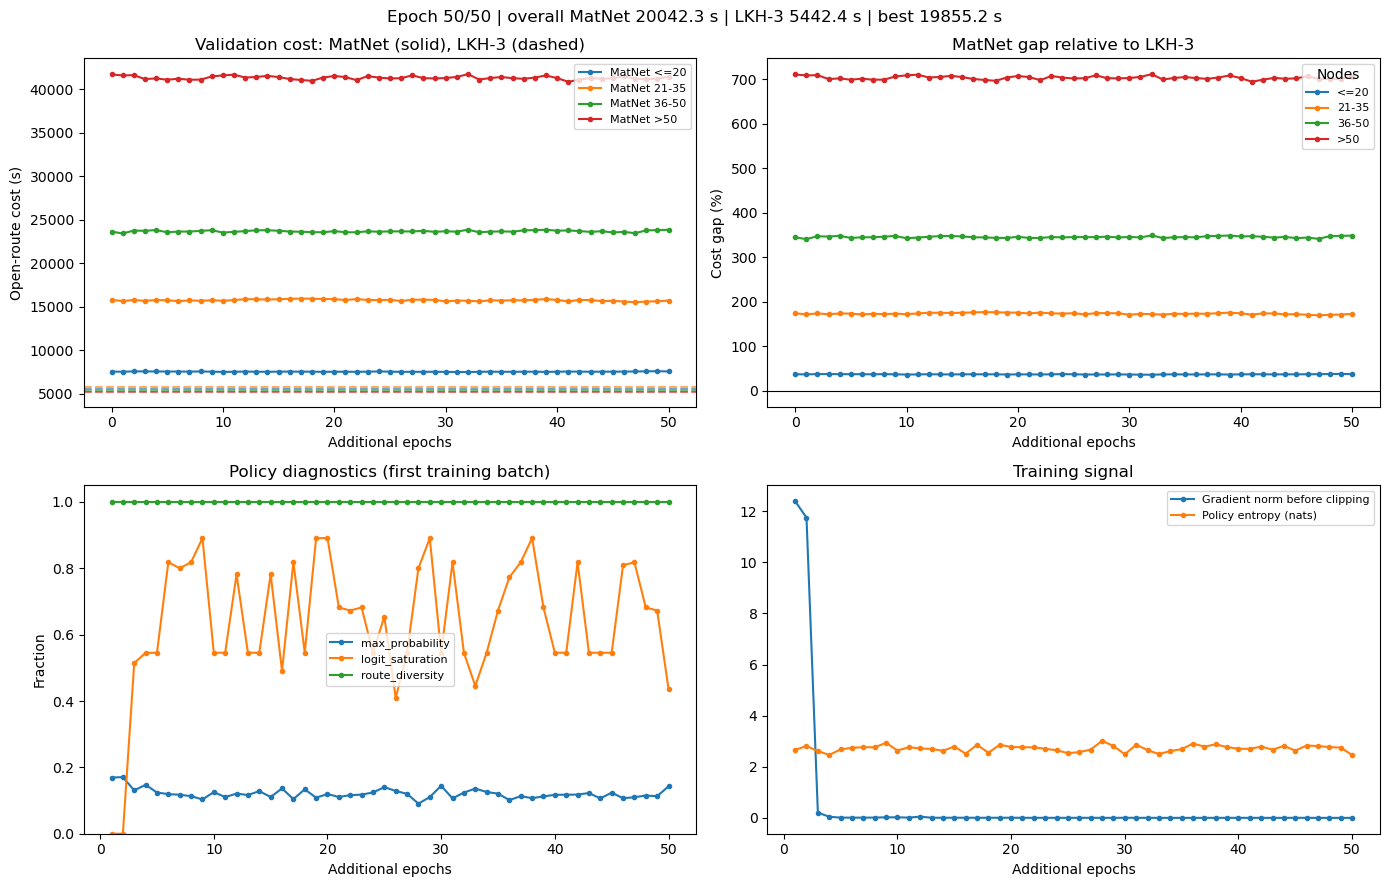

Done. Best val cost 19855.2490. Saved matnet_open_atsp_fromto_v2_lkhguide.pth


In [40]:
# MatNet retraining: group-safe split against the portfolio comparison.
# Run after cells 1-9. Starts fresh v2 weights, or resumes the v2 best checkpoint.
if __name__ == '__main__':
    import json
    import portfolio_sota as ps
    import TAPOCT_robustness_cell as rb
    from sklearn.model_selection import GroupShuffleSplit

    SEED = 42
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    with open('courier_training_checkpoint_fd_seconds.pkl', 'rb') as f:
        comparison_couriers = pickle.load(f)
    with open('epos_cache_fd.pkl', 'rb') as f:
        comparison_results = pickle.load(f)
    with open('global_properties_osrm_seconds.pkl', 'rb') as f:
        comparison_properties = pickle.load(f)
    courier_id = 35  # same courier and SEED as Portfolio_SOTA_training.ipynb
    replay_ids = set(rb.common_triplet_replay(comparison_results, ps.ALGORITHMS))
    common_ids = [pid for pid in dict.fromkeys(comparison_couriers[courier_id]['polygon_list'])
                  if pid in replay_ids and pid in AUG_global_map and pid in comparison_properties]
    _, _, test_ids = ps.grouped_partition(common_ids, AUG_global_map, SEED)
    heldout_sources = {ps.original_polygon_id(pid, AUG_global_map) for pid in test_ids}

    all_ids = [pid for pid in dict.fromkeys(basic_routes)
               if len(AUG_global_map[pid]['full map']) + 1 <= 120]
    eligible_ids = [pid for pid in all_ids
                    if ps.original_polygon_id(pid, AUG_global_map) not in heldout_sources]
    excluded = len(all_ids) - len(eligible_ids)
    if excluded == 0:
        print('No comparison polygons overlap MatNet training; split still checked')
    sources = np.array([ps.original_polygon_id(pid, AUG_global_map) for pid in eligible_ids])
    train_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=.30,
                                                 random_state=SEED).split(eligible_ids, groups=sources))
    train_ids = [eligible_ids[i] for i in train_idx]
    val_ids = [eligible_ids[i] for i in val_idx]
    assert heldout_sources.isdisjoint({ps.original_polygon_id(p, AUG_global_map)
                                      for p in train_ids + val_ids})
    MAX_NODES = max(len(AUG_global_map[p]['full map'])+1 for p in eligible_ids)
    print('Training', len(train_ids), 'validation', len(val_ids),
          'held-out groups excluded', excluded, 'max nodes', MAX_NODES)
    train_ds = ATSPDatasetMatNet(train_ids, AUG_global_map, distance_array, idx_dict,
                                 wh_point=0, permutation_mode='train', seed=SEED)
    val_ds = ATSPDatasetMatNet(val_ids, AUG_global_map, distance_array, idx_dict,
                               wh_point=0, permutation_mode='validation',
                               validation_repeats=3, seed=SEED)
    collate = make_collate(MAX_NODES)
    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, collate_fn=collate)
    val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, collate_fn=collate)

    # Guided run is a separate MatNet-LKH variant; the plain MatNet checkpoint is preserved.
    output = 'matnet_open_atsp_fromto_v2_lkhguide.pth'
    plain_output = 'matnet_open_atsp_fromto_v2.pth'
    model = MatNet(embed_dim=128, n_layers=5, n_heads=8, ff_dim=512)
    resume_guided = os.path.isfile(output)
    initial_weights = output if resume_guided else plain_output
    if os.path.isfile(initial_weights):
        model.load_state_dict(torch.load(initial_weights, map_location='cpu', weights_only=True))
        print('Starting with compatible weights:', initial_weights)
    torch.save(model.state_dict(), output)  # protect epoch-zero state
    prepare_lkh_teacher_routes(train_ds, runs=1)
    lkh_reference = validation_lkh_reference(val_ds, runs=5)  # computed once, not each epoch
    model, best, history = train_matnet_rl_gpu(
        model, train_loader, val_loader, num_epochs=50, lr=1e-4, device=device,
        lkh_reference=lkh_reference, checkpoint_path=output, plot_every=2,
        imitation_weight=0.0 if resume_guided else 0.05, imitation_epochs=20)
    with open('matnet_validation_vs_lkh_history.json', 'w') as f:
        json.dump(history, f, indent=2)
    with open('matnet_open_atsp_fromto_v2_lkhguide_manifest.json', 'w') as f:
        json.dump({'seed': SEED, 'courier_id': courier_id,
                   'train_ids': train_ids, 'val_ids': val_ids,
                   'excluded_comparison_ids': excluded, 'best_validation_cost_s': best,
                   'training_permutation': 'fresh order permutation; depot fixed',
                   'validation_permutations_per_polygon': 3,
                   'architecture': 'from/current+start query; to/column candidate keys',
                   'reinforce_sign': 'positive cost advantage',
                   'lkh_guidance': ('resumed guided weights with pure REINFORCE' if resume_guided
                                    else 'teacher-forced cross entropy, weight 0.05, 20-epoch decay'),
                   'train_matrix_return_to_depot_s': 0.0}, f, indent=2)
    print(f'Done. Best val cost {best:.4f}. Saved {output}')


In [55]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import copy
import random
import re
from typing import Tuple, List, Optional
from torch.utils.data import Dataset, DataLoader, Sampler
from collections import defaultdict

# ==========================================
# ENCODER (Unchanged)
# ==========================================
class NLNS_EncoderLayer(nn.Module):
    def __init__(self, embed_dim: int = 128, n_heads: int = 8):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = embed_dim // n_heads
        self.Wq = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wk = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wv = nn.Linear(embed_dim, embed_dim, bias=False)
        self.Wout = nn.Linear(embed_dim, embed_dim, bias=False)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ff = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4), nn.ReLU(),
            nn.Linear(embed_dim * 4, embed_dim)
        )

    def forward(self, x, dist_matrix=None, mask=None):
        B, N, _ = x.shape
        residual = x
        Q = self.Wq(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        K = self.Wk(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        V = self.Wv(x).view(B, N, self.n_heads, self.head_dim).transpose(1, 2)
        
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.head_dim)
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        out = self.Wout(out)
        
        x = self.norm1(residual + out)
        x = self.norm2(x + self.ff(x))
        return x

class NLNS_Encoder(nn.Module):
    def __init__(self, embed_dim=128, n_layers=3, n_heads=8):
        super().__init__()
        self.feat_proj = nn.Linear(2, embed_dim)
        self.layers = nn.ModuleList([NLNS_EncoderLayer(embed_dim, n_heads) for _ in range(n_layers)])
        
    def forward(self, dist_matrix):
        B, N, _ = dist_matrix.shape
        row_mean = dist_matrix.mean(dim=-1, keepdim=True)
        row_std = dist_matrix.std(dim=-1, keepdim=True)
        feats = torch.cat([row_mean, row_std], dim=-1)
        
        x = self.feat_proj(feats)
        for layer in self.layers:
            x = layer(x)
        return x

# ==========================================
# DECODER (Fixed for Insertion Logic)
# ==========================================
class NLNS_RepairDecoder(nn.Module):
    def __init__(self, embed_dim=128):
        super().__init__()
        E = embed_dim
        # Project the edge embeddings (head, tail)
        self.edge_proj = nn.Linear(2 * E, E, bias=False)
        # Query projection for the node to be inserted
        self.q_proj = nn.Linear(E, E, bias=False)
        # Key projection for the edges
        self.k_proj = nn.Linear(E, E, bias=False)
        # Projection for the cost change
        self.cost_proj = nn.Linear(1, E, bias=False)
        self.scale = E ** 0.5

    def forward(self, v_idx, v_emb, partial_tour_embs, partial_tour_indices, dist_matrix):
        B, L, E = partial_tour_embs.shape
        device = dist_matrix.device
        
        # Get the next node IDs in the partial tour (circular shift)
        # We still need this for looking up exact distances in the dist_matrix later
        next_indices = torch.roll(partial_tour_indices, shifts=-1, dims=1)
        
        # Embeddings of the head and tail of each edge in the partial tour
        head_e = partial_tour_embs
        
        # FIX: Roll the embeddings directly along the sequence dimension (dim=1).
        # DO NOT use torch.gather with next_indices here, because next_indices contains 
        # node IDs (0 to N-1), not sequence positions (0 to L-1).
        tail_e = torch.roll(partial_tour_embs, shifts=-1, dims=1)
        
        # Combine head and tail to form edge embeddings
        edge_e = self.edge_proj(torch.cat([head_e, tail_e], dim=-1)) # (B, L, E)
        
        # Query from the node to be inserted
        q = self.q_proj(v_emb) # (B, 1, E)
        k = self.k_proj(edge_e) # (B, L, E)
        
        # Attention scores between the node to insert and the edges
        attn_scores = torch.matmul(q, k.transpose(1, 2)).squeeze(1) / self.scale # (B, L)
        
        # Calculate the exact cost change for inserting v into each edge
        bidx = torch.arange(B, device=device).view(B, 1)
        v_idx_exp = v_idx.view(B, 1).expand(B, L)
        
        # Cost from p_i to v (using node IDs)
        cost_pv = dist_matrix[bidx, partial_tour_indices, v_idx_exp]
        # Cost from v to p_{i+1} (using node IDs)
        cost_vp = dist_matrix[bidx, v_idx_exp, next_indices]
        # Cost of the existing edge (p_i, p_{i+1}) (using node IDs)
        cost_pp = dist_matrix[bidx, partial_tour_indices, next_indices]
        
        # Change in tour length: Delta = d(p_i, v) + d(v, p_{i+1}) - d(p_i, p_{i+1})
        cost_change = cost_pv + cost_vp - cost_pp # (B, L)
        
        # Project cost change to embedding space to combine with attention
        cost_emb = self.cost_proj(cost_change.unsqueeze(-1)) # (B, L, E)
        
        # We want to minimize cost_change, so we subtract its contribution from the score
        cost_score = (q * cost_emb).sum(-1) / self.scale # (B, L)
        
        # Final scores: higher is better
        scores = attn_scores - cost_score
        
        return scores

# ==========================================================
# FULL NLNS MODEL (destroy + neural repair)
# ==========================================================
class NLNS_Model(nn.Module):
    def __init__(self, embed_dim=128, n_layers=3, n_heads=8):
        super().__init__()
        self.encoder = NLNS_Encoder(embed_dim, n_layers, n_heads)
        self.decoder = NLNS_RepairDecoder(embed_dim)
        self.embed_dim = embed_dim

    @staticmethod
    def destroy(tours, destroy_fraction=0.2, start_idx=0):
        B, N = tours.shape
        k = max(1, int(N * destroy_fraction))
        
        removed_nodes_batch = []
        partial_tours_batch = []
        
        for b in range(B):
            tour_b = tours[b].tolist()
            candidates = [node for node in tour_b if node != start_idx]
            removed = random.sample(candidates, min(k, len(candidates)))
            removed_nodes_batch.append(removed)
            
            partial = [node for node in tour_b if node not in removed]
            partial_tours_batch.append(partial)
            
        return removed_nodes_batch, partial_tours_batch

    def repair(self, dist_matrix, tours, destroy_fraction=0.2, start_idx=0, greedy=False, temperature=1.0):
        B, N = tours.shape
        device = dist_matrix.device
        
        node_embs = self.encoder(dist_matrix)
        removed_nodes_batch, partial_tours_batch = self.destroy(tours, destroy_fraction, start_idx)
        
        batch_logp = []
        batch_ent = []
        final_tours = []
        costs = []
        
        for b in range(B):
            partial_tour = partial_tours_batch[b]
            removed_nodes = removed_nodes_batch[b]
            random.shuffle(removed_nodes)
            
            traj_logps = []
            traj_ents = []
            
            for v in removed_nodes:
                # Prepare inputs for the decoder
                v_idx = torch.tensor([v], dtype=torch.long, device=device)
                v_emb = node_embs[b, v].unsqueeze(0).unsqueeze(0) # (1, 1, E)
                
                partial_tour_indices = torch.tensor(partial_tour, dtype=torch.long, device=device).unsqueeze(0) # (1, L)
                partial_tour_embs = node_embs[b, partial_tour_indices.squeeze(0)].unsqueeze(0) # (1, L, E)
                
                dist_b = dist_matrix[b].unsqueeze(0) # (1, N, N)
                
                # Get insertion scores for all L possible positions in the partial tour
                scores = self.decoder(v_idx, v_emb, partial_tour_embs, partial_tour_indices, dist_b).squeeze(0) # (L,)
                
                if greedy:
                    pos_idx = torch.argmax(scores).item()
                    log_prob = torch.tensor(0.0, device=device)
                    ent = torch.tensor(0.0, device=device)
                else:
                    probs = F.softmax(scores / temperature, dim=-1)
                    probs = torch.clamp(probs, min=1e-8, max=1.0)
                    dist = torch.distributions.Categorical(probs)
                    
                    pos_idx_tensor = dist.sample()
                    pos_idx = pos_idx_tensor.item()
                    log_prob = dist.log_prob(pos_idx_tensor)
                    ent = dist.entropy()
                    
                traj_logps.append(log_prob)
                traj_ents.append(ent)
                
                # Insert v into the partial tour after the chosen position
                partial_tour.insert(pos_idx + 1, v)
                
            final_tours.append(partial_tour)
            batch_logp.append(torch.stack(traj_logps).sum() if traj_logps else torch.tensor(0.0, device=device))
            batch_ent.append(torch.stack(traj_ents).sum() if traj_ents else torch.tensor(0.0, device=device))
            
            cost = 0.0
            for i in range(len(partial_tour) - 1):
                cost += dist_matrix[b, partial_tour[i], partial_tour[i+1]].item()
            costs.append(cost)
            
        final_tours_tensor = torch.tensor(final_tours, dtype=torch.long, device=device)
        costs_tensor = torch.tensor(costs, dtype=torch.float, device=device)
        total_logp = torch.stack(batch_logp) # Shape (B,)
        total_ent = torch.stack(batch_ent)   # Shape (B,)
            
        return final_tours_tensor, costs_tensor, total_logp, total_ent

    @torch.no_grad()
    def solve(self, dist_matrix, init_tours, destroy_fraction=0.2, n_iterations=100,
              start_idx=0, sample=True, temperature=1.0):
        self.eval()
        B, N = init_tours.shape
        device = dist_matrix.device
        best_tours = init_tours.clone()
        idx = torch.arange(B, device=device)
        
        best_cost = torch.zeros(B, device=device)
        for i in range(N - 1):
            best_cost += dist_matrix[idx, best_tours[:, i], best_tours[:, i + 1]]

        cur_tours, cur_cost = best_tours.clone(), best_cost.clone()
        
        for _ in range(n_iterations):
            new_tours, new_cost, _, _ = self.repair(
                dist_matrix, cur_tours, destroy_fraction=destroy_fraction,
                start_idx=start_idx, greedy=not sample, temperature=temperature)
            
            improved = new_cost < cur_cost
            cur_tours = torch.where(improved.unsqueeze(1), new_tours, cur_tours)
            cur_cost  = torch.where(improved, new_cost, cur_cost)
            
            better = cur_cost < best_cost
            best_tours = torch.where(better.unsqueeze(1), cur_tours, best_tours)
            best_cost  = torch.where(better, cur_cost, best_cost)
            
        return best_tours, best_cost

def train_NLNS_rl(model, train_loader, val_loader, num_epochs=50, lr=1e-4,
                  device='cpu', destroy_fraction=0.2, temperature=1.0, grad_clip=1.0,
                  entropy_coef=0.01, start_idx=0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state = float('inf'), None

    for ep in range(num_epochs):
        print("\n" + "="*60)
        print(f'PROCEEDING WITH EPOCH {ep}')
        print("="*60)
        
        model.train()
        run_cost, n_seen = 0.0, 0
        
        for batch in train_loader:
            try:
                dist = batch['dist_matrices'].to(device)
                warm = batch['warm_tours'].to(device)
                
                if dist.shape[0] < 2:
                    continue
    
                _, cost, logp, ent = model.repair(dist, warm, destroy_fraction=destroy_fraction,
                                                  start_idx=start_idx, greedy=False, temperature=temperature)
                
                with torch.no_grad():
                    _, baseline, _, _ = model.repair(dist, warm, destroy_fraction=destroy_fraction,
                                                     start_idx=start_idx, greedy=True)
                
                # cost and baseline are now tensors of shape (B,)
                adv = cost - baseline
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
                
                # REINFORCE loss: minimize adv * logp to decrease prob of bad actions
                loss = (adv.detach() * logp).mean() - entropy_coef * ent.mean()
    
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                opt.step()
                
                run_cost += cost.mean().item()
                n_seen += 1
                
            except Exception as e:
                print(f"Error in batch: {e}")
                import traceback
                traceback.print_exc()

        train_cost = run_cost / max(n_seen, 1)

        model.eval()
        vrun, vn = 0.0, 0
        with torch.no_grad():
            for batch in val_loader:
                dist = batch['dist_matrices'].to(device)
                warm = batch['warm_tours'].to(device)
                
                _, vc, _, _ = model.repair(dist, warm, destroy_fraction=destroy_fraction,
                                           start_idx=start_idx, greedy=True)
                vrun += vc.mean().item()
                vn += 1
                
        val_cost = vrun / max(vn, 1)

        print(f"Epoch {ep+1:3d}/{num_epochs} | train(repair) {train_cost:8.4f} | val(NLNS) {val_cost:8.4f}")
        
        if val_cost < best_val:
            best_val = val_cost
            best_state = copy.deepcopy(model.state_dict())
            print(f"   new best (val {best_val:.4f})")

    if best_state is not None: 
        model.load_state_dict(best_state)
        
    return model, best_val

def get_basic_order_ID(point):
    sliced_string = re.split(r'-', str(point))
    basic_point = sliced_string[-1]
    return int(basic_point)

class ATSPDatasetFloatingDepot(Dataset):
    def __init__(self, poly_ids, AUG_global_map, orders_dict,
                 distance_array, idx_dict, max_resample=5):
        self.ids = list(poly_ids)
        self.maps = AUG_global_map
        self.orders_dict = orders_dict
        self.distance_array = distance_array
        self.idx_dict = idx_dict
        self.max_resample = max_resample
        self.length = {pid: len(self.maps[pid]['full map']) + 1 for pid in self.ids}

    def __len__(self):
        return len(self.ids)

    def _build(self, pid, robust_wh):
        full_map    = self.maps[pid]['full map']
        base_orders = [get_basic_order_ID(o) for o in full_map]
        N = len(full_map)

        M = np.zeros((N + 1, N + 1), dtype=int)
        M[1:, 1:] = self.maps[pid]['distance matrix']
        M[0, 1:]  = [int(get_distance(self.distance_array, self.idx_dict, robust_wh, o))
                     for o in base_orders]
        M[1:, 0]  = 0
        np.fill_diagonal(M, 0)

        # FIX: Unpack 2 values instead of 4
        route, route_cost = solve_lkh_atsp(full_map, robust_wh, M)
        if robust_wh not in base_orders:
            route_with_wh = [robust_wh] + list(route)
            aug_points = [robust_wh] + list(full_map)
        else:
            route_with_wh = route
            aug_points = full_map

        id2idx = {oid: i for i, oid in enumerate(aug_points)}
        idxd = [id2idx[o] for o in route_with_wh]

        s = idxd.index(0); idxd = idxd[s:] + idxd[:s]
        assert sorted(idxd) == list(range(N + 1)), \
            f"{pid}: warm tour not a permutation (diff={set(range(N+1)) ^ set(idxd)})"
        return M, idxd

    def __getitem__(self, i):
        pid = self.ids[i]
        orig = set(get_basic_order_ID(o) for o in self.maps[pid]['full map'])
        feasible = list(set(self.orders_dict.keys()) - orig)

        for _ in range(self.max_resample):
            wh = random.choice(feasible)
            try:
                M, idxd = self._build(pid, wh)
                break
            except Exception:
                continue
        else:
            N = len(self.maps[pid]['full map'])
            wh = random.choice(feasible)
            M = np.zeros((N + 1, N + 1), dtype=int)
            M[1:, 1:] = self.maps[pid]['distance matrix']
            M[0, 1:]  = [int(get_distance(self.distance_array, self.idx_dict, wh,
                              get_basic_order_ID(o))) for o in self.maps[pid]['full map']]
            np.fill_diagonal(M, 0)
            idxd = list(range(N + 1))

        return {'poly_id': pid,
                'dist_matrices': torch.as_tensor(M, dtype=torch.float),
                'warm_tours':    torch.as_tensor(idxd, dtype=torch.long)}

class SizeBucketSampler(Sampler):
    def __init__(self, dataset, batch_size, shuffle=True, drop_singletons=True):
        self.bs, self.shuffle, self.drop1 = batch_size, shuffle, drop_singletons
        self.buckets = defaultdict(list)
        for i, pid in enumerate(dataset.ids):
            self.buckets[dataset.length[pid]].append(i)
            
    def __iter__(self):
        batches = []
        for idxs in self.buckets.values():
            idxs = idxs[:]
            if self.shuffle: random.shuffle(idxs)
            for j in range(0, len(idxs), self.bs):
                b = idxs[j:j + self.bs]
                if self.drop1 and len(b) < 2:
                    continue
                batches.append(b)
        if self.shuffle: random.shuffle(batches)
        return iter(batches)
        
    def __len__(self):
        tot = 0
        for v in self.buckets.values():
            nb = (len(v) + self.bs - 1) // self.bs
            if self.drop1 and len(v) % self.bs == 1: nb -= 1
            tot += nb
        return tot

def collate_uniform(items):
    return {'poly_id': [it['poly_id'] for it in items],
            'dist_matrices': torch.stack([it['dist_matrices'] for it in items]),
            'warm_tours':    torch.stack([it['warm_tours']    for it in items])}

def run_nlns_pipeline_lkh(cost_matrix, orders, model,
                      start_idx=0, destroy_fraction=0.2, n_iterations=200, device='cpu'):
    model.eval()
    # FIX: Unpack 2 values instead of 4
    warm, warm_cost = solve_lkh_atsp(orders, orders[0], cost_matrix)
    
    id2idx = {oid: i for i, oid in enumerate(orders)}
    idxd = [id2idx[o] for o in warm]
    
    dist = torch.tensor(cost_matrix, dtype=torch.float, device=device).unsqueeze(0)
    warm_t = torch.tensor(idxd, dtype=torch.long, device=device).unsqueeze(0)

    best_tours, best_cost = model.solve(
        dist, warm_t, destroy_fraction=destroy_fraction,
        n_iterations=n_iterations, start_idx=start_idx, sample=True)

    return (best_tours.squeeze(0).cpu().numpy(),
            float(best_cost.squeeze(0).cpu()),
            float(warm_cost))

def run_nlns_pipeline_chr(cost_matrix, orders, model,
                      start_idx=0, destroy_fraction=0.2, n_iterations=200, device='cpu'):
    model.eval()
    # FIX: Unpack 2 values instead of 4
    warm, warm_cost, _, _ = solve_TSP_Christofides_inner(orders, orders[0], cost_matrix)
    
    id2idx = {oid: i for i, oid in enumerate(orders)}
    idxd = [id2idx[o] for o in warm]
    
    dist = torch.tensor(cost_matrix, dtype=torch.float, device=device).unsqueeze(0)
    warm_t = torch.tensor(idxd, dtype=torch.long, device=device).unsqueeze(0)

    best_tours, best_cost = model.solve(
        dist, warm_t, destroy_fraction=destroy_fraction,
        n_iterations=n_iterations, start_idx=start_idx, sample=True)

    return (best_tours.squeeze(0).cpu().numpy(),
            float(best_cost.squeeze(0).cpu()),
            float(warm_cost))

In [36]:
# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == '__main__':
    # NOTE: Ensure basic_routes, AUG_global_map, orders_dict, distance_array, idx_dict 
    # are defined in your notebook environment before running this block.
    
    random.seed(42)
    by_size = defaultdict(list)
    for pid in basic_routes.keys():
        by_size[len(AUG_global_map[pid]['full map']) + 1].append(pid)

    train_ids, test_ids = [], []
    for size, ids in by_size.items():
        random.shuffle(ids)
        s = int(round(len(ids) * 0.7))
        train_ids += ids[:s]; test_ids += ids[s:]

    BATCH_SIZE = 4
    train_ds = ATSPDatasetFloatingDepot(train_ids, AUG_global_map, orders_dict, distance_array, idx_dict)
    test_ds  = ATSPDatasetFloatingDepot(test_ids,  AUG_global_map, orders_dict, distance_array, idx_dict)
    
    train_loader = DataLoader(train_ds,
        batch_sampler=SizeBucketSampler(train_ds, BATCH_SIZE, shuffle=True),
        collate_fn=collate_uniform, num_workers=0)
    val_loader = DataLoader(test_ds,
        batch_sampler=SizeBucketSampler(test_ds, BATCH_SIZE, shuffle=False, drop_singletons=False),
        collate_fn=collate_uniform, num_workers=0)

    model_NLNS = NLNS_Model(embed_dim=128, n_layers=3, n_heads=8)
    model_TNLNS, best = train_NLNS_rl(model_NLNS, train_loader, val_loader, device='cpu')
    
    torch.save(model_TNLNS.state_dict(), 'nlns_open_atsp_lkh.pth')
    print(f"Done. Best val cost: {best:.4f}")


PROCEEDING WITH EPOCH 0
Epoch   1/50 | train(repair) 7286.1174 | val(NLNS) 5956.0396
   new best (val 5956.0396)

PROCEEDING WITH EPOCH 1
Epoch   2/50 | train(repair) 5835.4804 | val(NLNS) 5894.4231
   new best (val 5894.4231)

PROCEEDING WITH EPOCH 2
Epoch   3/50 | train(repair) 12044.9594 | val(NLNS) 20747.0212

PROCEEDING WITH EPOCH 3
Epoch   4/50 | train(repair) 19215.8878 | val(NLNS) 20907.4765

PROCEEDING WITH EPOCH 4
Epoch   5/50 | train(repair) 19226.9630 | val(NLNS) 20942.7399

PROCEEDING WITH EPOCH 5
Epoch   6/50 | train(repair) 19206.4517 | val(NLNS) 20948.1680

PROCEEDING WITH EPOCH 6
Epoch   7/50 | train(repair) 19223.8952 | val(NLNS) 20943.1257

PROCEEDING WITH EPOCH 7
Epoch   8/50 | train(repair) 19267.8564 | val(NLNS) 20887.8356

PROCEEDING WITH EPOCH 8
Epoch   9/50 | train(repair) 19210.5255 | val(NLNS) 20906.1179

PROCEEDING WITH EPOCH 9
Epoch  10/50 | train(repair) 19356.1960 | val(NLNS) 20934.6432

PROCEEDING WITH EPOCH 10
Epoch  11/50 | train(repair) 15422.7992 | 

In [61]:
result = {'BC_route_cost': [],
          'BC_comp_time': [],
          'pol': [],
          'NLNS_route_cost': [],
          'NLNS_comp_time': [],
          'Chr_route_cost': [],
          'Chr_comp_time': [],
          'lkh_route_cost': [],
          'lkh_comp_time': []
         }

device = 'gpu'

NLNS_PATH_LKH = r'C:\Users\Administrator\nlns_open_atsp_lkh.pth'

NLNS_MODEL_LKH = NLNS_Model(embed_dim=128, n_layers=3, n_heads=8)
NLNS_MODEL_LKH.load_state_dict(torch.load(NLNS_PATH_LKH, weights_only=True))

NLNS_MODEL.eval()
print("✅ NLNS initialized on", device)

for poly_id in tqdm(basic_routes.keys()):
    
    polygon = poly_id
    wh_point = 0
    orders = AUG_global_map[polygon]['full map']
    
    ideal_matrix = AUG_global_map[polygon]['distance matrix'] #here we use AUG_global_map or analogue
    orders = [wh_point] + AUG_global_map[polygon]['full map']
    
    N = len(AUG_global_map[polygon]['full map'])
    
    M = np.zeros((N + 1, N + 1), dtype=int)
    M[1:, 1:] = ideal_matrix
    M[0, 1:]  = [int(get_distance(distance_array, idx_dict, wh_point, get_basic_order_ID(o))) for o in AUG_global_map[polygon]['full map']]
    np.fill_diagonal(M, 0)
    idxd = list(range(N + 1))

    start_t = time.time()
    try:
        route, route_cost, _, _ = solve_TSP_branch_and_cut(orders, wh_point, M, max_time_s=5)
        end_t_BC = time.time() - start_t
    except Exception as e:
        route, route_cost = 0, 0
        end_t_BC = 0

    start_t = time.time()
    tour_chr, cost_chr, _, _ = solve_TSP_Christofides_inner(orders, orders[0], M)
    end_chr = time.time() - start_t

    start_t = time.time()
    tour_lkh, cost_lkh = solve_lkh_atsp(orders, orders[0], M)
    end_lkh = time.time() - start_t
    
    start_t = time.time()
    tour, nlns_cost, _ = run_nlns_pipeline_lkh(
         M, orders, NLNS_MODEL_LKH, start_idx=0)
    end_t_NLNS = time.time() - start_t

    result['BC_route_cost'].append(route_cost)
    result['BC_comp_time'].append(end_t_BC)
    result['pol'].append(poly_id)
    result['NLNS_route_cost'].append(nlns_cost)
    result['NLNS_comp_time'].append(end_t_NLNS)
    result['Chr_route_cost'].append(cost_chr)
    result['Chr_comp_time'].append(end_chr)
    result['lkh_route_cost'].append(cost_lkh)
    result['lkh_comp_time'].append(end_lkh)

✅ NLNS initialized on gpu


100%|██████████| 2064/2064 [2:22:49<00:00,  4.15s/it]  


In [57]:
add_r = {'NLNS_route_cost_chr': [],
          'NLNS_comp_time_chr': []
        }

device = 'gpu'

NLNS_PATH_CHR = r'C:\Users\Administrator\nlns_open_atsp_chr.pth'

NLNS_MODEL = NLNS_Model(embed_dim=128, n_layers=3, n_heads=8)
NLNS_MODEL.load_state_dict(torch.load(NLNS_PATH_CHR, weights_only=True))

NLNS_MODEL.eval()
print("✅ NLNS initialized on", device)

for poly_id in tqdm(basic_routes.keys()):
    
    polygon = poly_id
    wh_point = 0
    orders = AUG_global_map[polygon]['full map']
    
    ideal_matrix = AUG_global_map[polygon]['distance matrix'] #here we use AUG_global_map or analogue
    orders = [wh_point] + AUG_global_map[polygon]['full map']
    
    N = len(AUG_global_map[polygon]['full map'])
    
    M = np.zeros((N + 1, N + 1), dtype=int)
    M[1:, 1:] = ideal_matrix
    M[0, 1:]  = [int(get_distance(distance_array, idx_dict, wh_point, get_basic_order_ID(o))) for o in AUG_global_map[polygon]['full map']]
    np.fill_diagonal(M, 0)
    idxd = list(range(N + 1))

    start_t = time.time()
    tour, nlns_cost, _ = run_nlns_pipeline_chr(
         M, orders, NLNS_MODEL, start_idx=0)
    end_t_NLNS = time.time() - start_t

    add_r['NLNS_route_cost_chr'].append(nlns_cost)
    add_r['NLNS_comp_time_chr'].append(end_t_NLNS)

✅ NLNS initialized on gpu


100%|██████████| 2064/2064 [59:16<00:00,  1.72s/it] 


In [62]:
nulls = []
for i, item in enumerate(result['BC_route_cost']):
    if item == 0:
        nulls.append(i)

In [63]:
len(nulls)

19

In [66]:
relative_cost_diff_BC = []
relative_time_diff_BC = []
relative_cost_diff_chr = []
relative_time_diff_chr = []
relative_cost_diff_lkh = []
relative_time_diff_lkh = []
relative_cost_diff_lkh_chr = []
relative_time_diff_lkh_chr = []
relative_cost_diff_NLNS_chr_chr = []
relative_time_diff_NLNS_chr_chr = []

for i in range(len(result['BC_route_cost'])):
    if i not in nulls:
        relative_cost_diff_BC.append(result['NLNS_route_cost'][i] - result['BC_route_cost'][i])
        relative_time_diff_BC.append(result['NLNS_comp_time'][i] - result['BC_comp_time'][i])
        relative_cost_diff_chr.append(result['NLNS_route_cost'][i] - result['Chr_route_cost'][i])
        relative_time_diff_chr.append(result['NLNS_comp_time'][i] - result['Chr_comp_time'][i])
        relative_cost_diff_lkh.append(result['NLNS_route_cost'][i] - result['lkh_route_cost'][i])
        relative_time_diff_lkh.append(result['NLNS_comp_time'][i] - result['lkh_comp_time'][i])
        relative_cost_diff_lkh_chr.append(result['NLNS_route_cost'][i] - add_r['NLNS_route_cost_chr'][i])
        relative_time_diff_lkh_chr.append(result['NLNS_comp_time'][i] - add_r['NLNS_comp_time_chr'][i])
        relative_cost_diff_NLNS_chr_chr.append(add_r['NLNS_route_cost_chr'][i] - result['Chr_route_cost'][i])
        relative_time_diff_NLNS_chr_chr.append(add_r['NLNS_comp_time_chr'][i] - result['Chr_comp_time'][i])

print(f"Mean route efficiency gap vs BC is {np.mean(relative_cost_diff_BC)/7200*100:.2f}%: higher -> worse route than BKS")
print(f"Mean comp time gap vs BC is {(np.mean(relative_time_diff_BC))/5*100:.2f}%: lower -> less comp.time")
print(f"Mean route efficiency gap vs Christofides is {np.mean(relative_cost_diff_chr)/7200*100:.2f}%: higher -> worse route than Chr")
print(f"Mean comp time gap vs Christofides is {(np.mean(relative_time_diff_chr))/5*100:.2f}%: lower -> less comp.time than Chr")
print(f"Mean route efficiency gap vs LKH3 is {np.mean(relative_cost_diff_lkh)/7200*100:.5f}%: higher -> worse route than lkh")
print(f"Mean comp time gap vs LKH3 is {(np.mean(relative_time_diff_lkh))/5*100:.2f}%: lower -> less comp.time than lkh")
print(f"Mean route efficiency gap NLNS LKH3 vs NLNS chr is {np.mean(relative_cost_diff_lkh_chr)/7200*100:.5f}%: higher -> worse route than lkh")
print(f"Mean comp time gap NLNS LKH3 vs NLNS chr is {(np.mean(relative_time_diff_lkh_chr))/5*100:.2f}%: lower -> less comp.time than lkh")
print(f"Mean route efficiency gap NLNS chr vs chr is {np.mean(relative_cost_diff_NLNS_chr_chr)/7200*100:.5f}%: higher -> worse route than chr")
print(f"Mean comp time gap NLNS chr vs chr is {(np.mean(relative_time_diff_NLNS_chr_chr))/5*100:.2f}%: lower -> less comp.time than chr")

Mean route efficiency gap vs BC is 0.00%: higher -> worse route than BKS
Mean comp time gap vs BC is -4.37%: lower -> less comp.time
Mean route efficiency gap vs Christofides is -2.33%: higher -> worse route than Chr
Mean comp time gap vs Christofides is 33.65%: lower -> less comp.time than Chr
Mean route efficiency gap vs LKH3 is -0.00003%: higher -> worse route than lkh
Mean comp time gap vs LKH3 is 32.89%: lower -> less comp.time than lkh
Mean route efficiency gap NLNS LKH3 vs NLNS chr is -1.69870%: higher -> worse route than lkh
Mean comp time gap NLNS LKH3 vs NLNS chr is 0.53%: lower -> less comp.time than lkh
Mean route efficiency gap NLNS chr vs chr is -0.62815%: higher -> worse route than chr
Mean comp time gap NLNS chr vs chr is 33.12%: lower -> less comp.time than chr


In [50]:
start_t = time.time()
tour, nlns_cost, warm_cost = run_nlns_pipeline(
         M, orders, model_TNLNS, start_idx=0)
print(f"Christofides: {warm_cost:.3f}  ->  NLNS: {nlns_cost:.3f},\n")
print(f"Inference time is {time.time() - start_t} seconds")

Christofides: 4366.000  ->  NLNS: 4366.000,

Inference time is 2.075406551361084 seconds
